# Load Data

In [3]:
import pandas as pd
import numpy as np

# Read from the the data to a CSV file to get rid of the data preprocessing step in the future.
data = pd.read_csv('median_amplitudes1.csv')
X = data.iloc[:, :-1]
Y = data.iloc[:, -1]

## Label Mapping for Night and Day time


### Day Time

0 - static <br>
1 - walking --- intrusion<br>
2 - bending & walking --- intrusion<br>
3 - crawling --- intrusion<br>
4 - sleeping<br>
5 - wake up<br>

In [5]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4 or prediction == 5:
		return 0	# Static environment
	else:
		return 1	# Intrusion

In [4]:
np.unique(Y)

array([0, 1, 2, 4, 5], dtype=int64)

In [7]:
Y_night = Y.copy()

for i in range (len(Y)):
	Y_night[i] = predictionMapping(Y[i])

In [8]:
np.unique(Y_night)

array([0, 1], dtype=int64)

# Feature extraction

In [19]:
sample_rate = 25  # Hz
window = 3    # Window size in seconds
window_size = window * sample_rate

num_subcarriers = 64

In [20]:
import numpy as np

features = []
labels = []

for window_start in range(0, len(X) - window_size + 1 , window_size):
    window_end = window_start + window_size
    window_data = X.iloc[window_start:window_end]
    
    # Calculate the variance of the amplitudes of each subcarrier within the sliding window
    V_w = np.var(window_data, axis=0)
    # Calculate the variance of all subcarriers' variances
    V = np.var(V_w)
    features.append([V])

    labels.append(Y_night.iloc[window_end - 1])   # Assuming the label for the window is the label of the last sample in the window

Convert features and labels to DataFrame

In [21]:
features_df = pd.DataFrame(features)
labels_df = pd.Series(labels)

# Classification Model

Split the data into training and validation sets

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(features_df, labels_df, test_size=0.2, random_state=42)

In [23]:
from hmmlearn import hmm

# Train HMM
n_components = len(np.unique(labels)) # Hidden states: No. of activity patterns

# ML MODEL
model = hmm.GaussianHMM(n_components=n_components, covariance_type="full", n_iter=1000)

# Fit the model on the training data
model.fit(X_train)


GaussianHMM(covariance_type='full', n_components=2, n_iter=1000)

In [24]:
# Decode the sequence of hidden states on validation data using Viterbi algorithm
logprob, hidden_states = model.decode(X_val.values, algorithm="viterbi")

In [25]:
# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

# Assuming binary classification: 1 for moving, 0 for static
accuracy = accuracy_score(y_val, hidden_states)
report = classification_report(y_val, hidden_states, zero_division=0)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)


Accuracy: 0.7170418006430869
Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.92      0.79       182
           1       0.79      0.43      0.56       129

    accuracy                           0.72       311
   macro avg       0.74      0.68      0.68       311
weighted avg       0.73      0.72      0.70       311



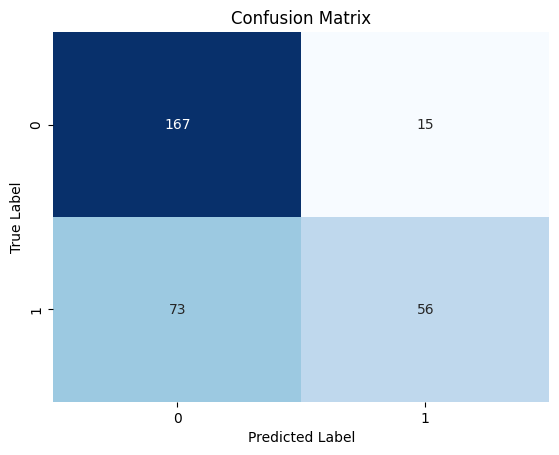

In [26]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, hidden_states)

# Plot the confusion matrix using seaborn heatmap
plt.figure()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()